# Chapter 3: Dimensionality Reduction Techniques
**Book:** *scikit-learn Cookbook, Third Edition* — John Sukup

## Learning objectives
- Explain why dimensionality reduction can be useful.
- Distinguish feature selection from feature extraction.
- Apply Principal Component Analysis (PCA) to the Wine dataset.
- Compare PCA and Linear Discriminant Analysis (LDA).
- Use t-SNE for exploratory visualization.
- Evaluate dimensionality reduction as part of a machine-learning workflow.

> This notebook follows the chapter's main topics and uses reproducible examples suitable for Google Colab. Run cells in order.

## 1. Imports and dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Classes:", list(wine.target_names))
display(X.head())
display(y.value_counts().sort_index().rename(index=dict(enumerate(wine.target_names))).to_frame("count"))

Dataset shape: (178, 13)
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,count
target,
class_0,59
class_1,71
class_2,48


## 2. Introduction to dimensionality reduction

Dimensionality reduction reduces the number of input dimensions. The book describes two broad approaches:

- **Feature selection:** keep a subset of the original features. Examples include statistical filters, Recursive Feature Elimination (RFE), and model-based selection.
- **Feature extraction:** transform the original features into a new, lower-dimensional representation. Examples include PCA, LDA, and t-SNE.

Potential benefits include simpler models, reduced storage or computation, less redundancy, and easier visualization. Reduction can also discard useful information, so compare results with the original feature set.

Original feature count: 13
Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


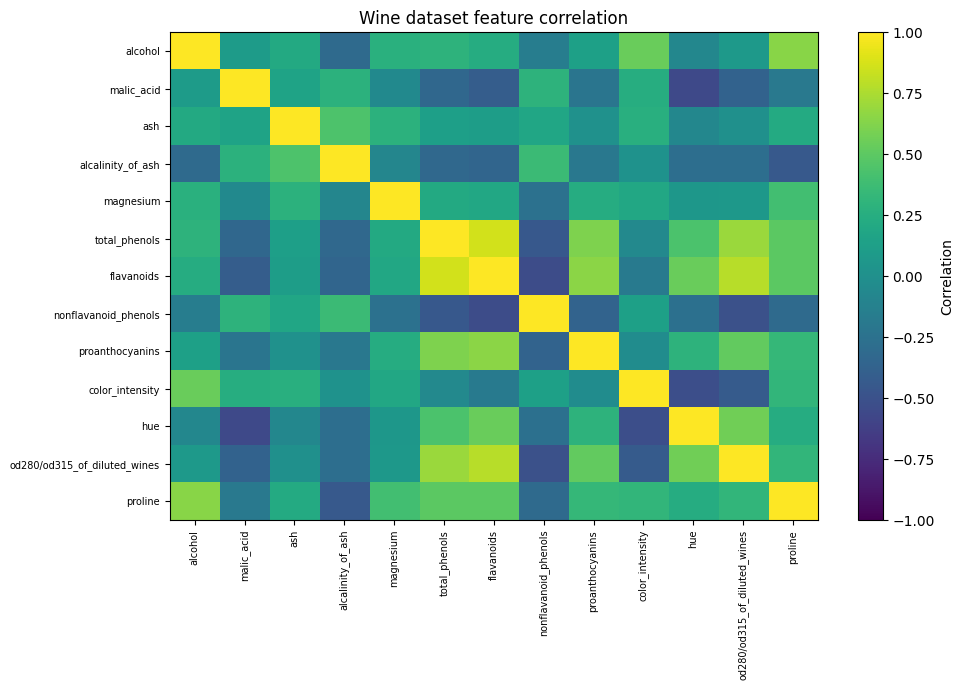

In [2]:
print(f"Original feature count: {X.shape[1]}")
print("Feature names:")
print(X.columns.tolist())

correlation = X.corr()
fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(correlation, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(X.columns)))
ax.set_xticklabels(X.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(X.columns)))
ax.set_yticklabels(X.columns, fontsize=7)
ax.set_title("Wine dataset feature correlation")
fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

## 3. Principal Component Analysis (PCA)

PCA is an **unsupervised feature-extraction** method. It identifies orthogonal directions that capture as much variance in the input features as possible. The first principal component captures the largest possible variance; subsequent components capture as much remaining variance as possible while staying orthogonal to earlier components.

Because Wine features use different units and ranges, standardize the features before PCA. PCA itself does not use the target labels when finding the components.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_all = PCA()
X_pca_all = pca_all.fit_transform(X_scaled)

variance_table = pd.DataFrame({
    "component": [f"PC{i}" for i in range(1, len(X.columns) + 1)],
    "explained_variance_ratio": pca_all.explained_variance_ratio_,
    "cumulative_variance": np.cumsum(pca_all.explained_variance_ratio_)
})

display(variance_table.head(10).round(4))

,component,explained_variance_ratio,cumulative_variance
0,PC1,0.3620,0.3620
1,PC2,0.1921,0.5541
2,PC3,0.1112,0.6653
3,PC4,0.0707,0.7360
4,PC5,0.0656,0.8016
5,PC6,0.0494,0.8510
6,PC7,0.0424,0.8934
7,PC8,0.0268,0.9202
8,PC9,0.0222,0.9424
9,PC10,0.0193,0.9617


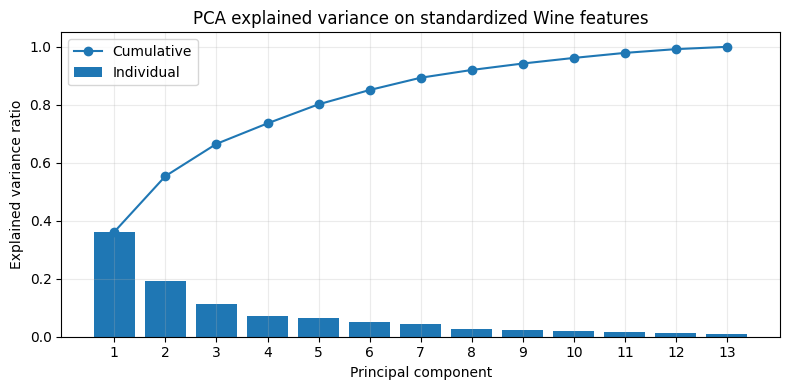

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
components = np.arange(1, len(pca_all.explained_variance_ratio_) + 1)
ax.bar(components, pca_all.explained_variance_ratio_, label="Individual")
ax.plot(components, np.cumsum(pca_all.explained_variance_ratio_), marker="o",
        label="Cumulative")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("PCA explained variance on standardized Wine features")
ax.set_xticks(components)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:** `explained_variance_ratio_` indicates the share of input variance represented by each component. The cumulative sum helps choose a component count for a chosen variance-retention target. Retaining more variance does not automatically guarantee better predictive performance.

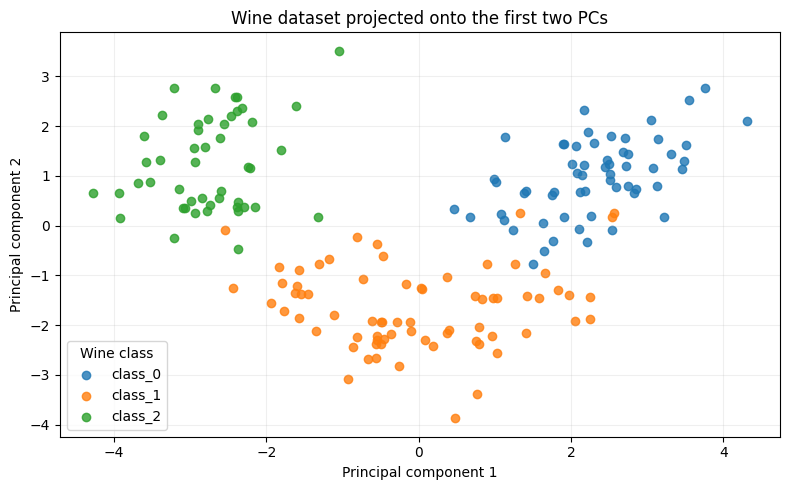

Variance retained by 2 components: 55.4%


In [5]:
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

pca_plot = pd.DataFrame({
    "PC1": X_pca_2[:, 0],
    "PC2": X_pca_2[:, 1],
    "class": y.map(dict(enumerate(wine.target_names))).to_numpy()
})

fig, ax = plt.subplots(figsize=(8, 5))
for class_name in wine.target_names:
    subset = pca_plot[pca_plot["class"] == class_name]
    ax.scatter(subset["PC1"], subset["PC2"], label=class_name, alpha=0.8)
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("Wine dataset projected onto the first two PCs")
ax.legend(title="Wine class")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Variance retained by 2 components:",
      f"{pca_2.explained_variance_ratio_.sum():.1%}")

### PCA for a predictive workflow

Fit the scaler and PCA only on the training split. A pipeline makes this separation automatic during model fitting and cross-validation.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

pca_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=3000))
])
pca_model.fit(X_train, y_train)
pca_predictions = pca_model.predict(X_test)

print("Number of PCA components retained:",
      pca_model.named_steps["pca"].n_components_)
print(f"Test accuracy after PCA: {accuracy_score(y_test, pca_predictions):.3f}")

Number of PCA components retained: 10
Test accuracy after PCA: 0.978


## 4. Linear Discriminant Analysis (LDA)

LDA is a **supervised** technique: it uses class labels and seeks projections that separate classes, balancing between-class separation against within-class variation. In contrast, PCA does not use labels and maximizes overall variance.

For classification problems, LDA can be used both as a dimensionality-reduction transformer and as a classifier. With \(K\) classes, the maximum number of LDA components is generally \(K - 1\).

In [7]:
X_train_scaled = StandardScaler().fit_transform(X_train)
X_test_scaled = StandardScaler().fit(X_train).transform(X_test)

lda_transformer = LinearDiscriminantAnalysis(n_components=2)
X_lda_train = lda_transformer.fit_transform(X_train_scaled, y_train)
X_lda_test = lda_transformer.transform(X_test_scaled)

print("LDA training shape:", X_lda_train.shape)
print("LDA test shape:", X_lda_test.shape)

LDA training shape: (133, 2)
LDA test shape: (45, 2)


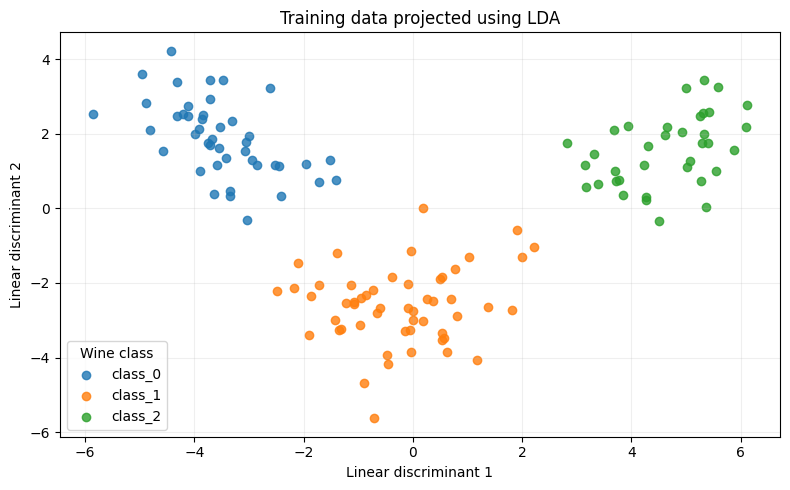

In [8]:
lda_plot = pd.DataFrame({
    "LD1": X_lda_train[:, 0],
    "LD2": X_lda_train[:, 1],
    "class": y_train.map(dict(enumerate(wine.target_names))).to_numpy()
})
fig, ax = plt.subplots(figsize=(8, 5))
for class_name in wine.target_names:
    subset = lda_plot[lda_plot["class"] == class_name]
    ax.scatter(subset["LD1"], subset["LD2"], label=class_name, alpha=0.8)
ax.set_xlabel("Linear discriminant 1")
ax.set_ylabel("Linear discriminant 2")
ax.set_title("Training data projected using LDA")
ax.legend(title="Wine class")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [9]:
lda_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=2)),
    ("classifier", LogisticRegression(max_iter=3000))
])
lda_model.fit(X_train, y_train)
lda_predictions = lda_model.predict(X_test)
print(f"Test accuracy with LDA transformation: {accuracy_score(y_test, lda_predictions):.3f}")

Test accuracy with LDA transformation: 0.978


### PCA versus LDA

| Property | PCA | LDA |
|---|---|---|
| Uses target labels to learn projection? | No | Yes |
| Main objective | Preserve variance | Improve class separation |
| Common use | Compression and exploratory visualization | Supervised projection and classification |
| Key caution | High variance may not be predictive | Requires class labels and assumptions about class distributions |

Compare methods using the same held-out split, and remember that results depend on the dataset and estimator.

## 5. t-SNE for visualization

t-distributed Stochastic Neighbor Embedding (t-SNE) is primarily useful for visualizing high-dimensional data in two or three dimensions. It attempts to preserve local neighborhood structure. Its axes do not have the direct variance interpretation of PCA, and distances between far-apart clusters should not be overinterpreted.

t-SNE is stochastic and can be computationally expensive. Standardize the features and set `random_state` for reproducibility.

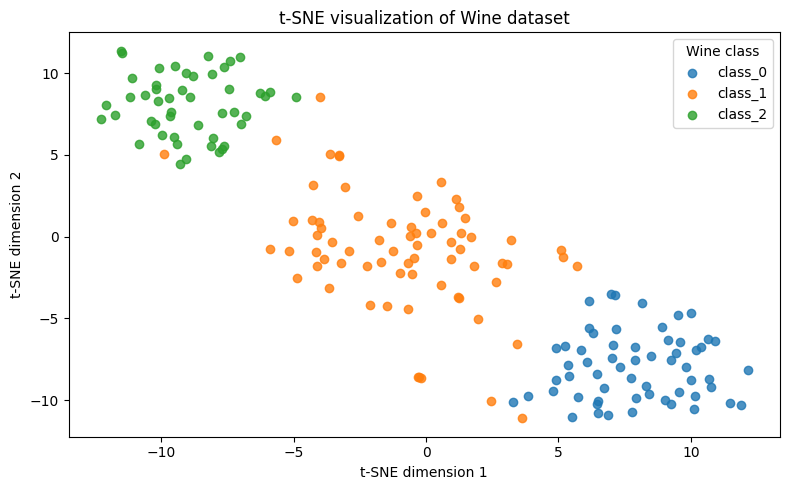

In [10]:
X_tsne_input = StandardScaler().fit_transform(X)
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE
)
X_tsne = tsne.fit_transform(X_tsne_input)

tsne_plot = pd.DataFrame({
    "dimension_1": X_tsne[:, 0],
    "dimension_2": X_tsne[:, 1],
    "class": y.map(dict(enumerate(wine.target_names))).to_numpy()
})

fig, ax = plt.subplots(figsize=(8, 5))
for class_name in wine.target_names:
    subset = tsne_plot[tsne_plot["class"] == class_name]
    ax.scatter(subset["dimension_1"], subset["dimension_2"],
               label=class_name, alpha=0.8)
ax.set_xlabel("t-SNE dimension 1")
ax.set_ylabel("t-SNE dimension 2")
ax.set_title("t-SNE visualization of Wine dataset")
ax.legend(title="Wine class")
plt.tight_layout()
plt.show()

**Interpretation:** the plot can reveal local groupings worth investigating, but it is not a classifier and does not prove that classes will be separable in a new dataset. Avoid comparing raw t-SNE coordinates across separate runs as if the axes were fixed.

## 6. Feature selection: RFE and model-based selection

Feature selection keeps original columns instead of creating new component axes. RFE repeatedly fits an estimator and removes less useful features until the requested number remains. `SelectFromModel` uses a fitted estimator's feature importance or coefficient magnitudes to select features.

Feature selection should be fitted on training data only. In this example, selection is followed by logistic regression in a pipeline.

In [11]:
selection_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("select", RFE(
        estimator=LogisticRegression(max_iter=3000),
        n_features_to_select=8
    )),
    ("classifier", LogisticRegression(max_iter=3000))
])

selection_model.fit(X_train, y_train)
selection_predictions = selection_model.predict(X_test)

selected_mask = selection_model.named_steps["select"].get_support()
selected_features = X.columns[selected_mask].tolist()

print("Selected features:")
print(selected_features)
print(f"Test accuracy with RFE: {accuracy_score(y_test, selection_predictions):.3f}")

Selected features:
['alcohol', 'ash', 'alcalinity_of_ash', 'flavanoids', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Test accuracy with RFE: 1.000


In [12]:
# Model-based selection using logistic-regression coefficients.
# This is a demonstration of the API; the selected set depends on the fitted model.
scaled_train = StandardScaler().fit_transform(X_train)
base_estimator = LogisticRegression(max_iter=3000).fit(scaled_train, y_train)
selector = SelectFromModel(base_estimator, threshold="mean", prefit=True)
model_selected = X.columns[selector.get_support()].tolist()

print("Features selected by SelectFromModel:")
print(model_selected)

Features selected by SelectFromModel:
['alcohol', 'ash', 'alcalinity_of_ash', 'flavanoids', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


## 7. Compare workflows on the same test set

In [13]:
# Baseline: all original features, scaled, with logistic regression.
baseline_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000))
])
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

comparison = pd.DataFrame({
    "workflow": [
        "All features + Logistic Regression",
        "PCA (95% variance) + Logistic Regression",
        "LDA (2 components) + Logistic Regression",
        "RFE (8 features) + Logistic Regression"
    ],
    "test_accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, pca_predictions),
        accuracy_score(y_test, lda_predictions),
        accuracy_score(y_test, selection_predictions)
    ]
})
display(comparison.sort_values("test_accuracy", ascending=False).reset_index(drop=True).round(3))

,workflow,test_accuracy
0,All features + Logistic Regression,1.000
1,RFE (8 features) + Logistic Regression,1.000
2,PCA (95% variance) + Logistic Regression,0.978
3,LDA (2 components) + Logistic Regression,0.978


This comparison is illustrative, not a universal ranking. Use cross-validation and task-appropriate metrics for robust model selection. Dimensionality reduction can improve speed or visualization even when accuracy does not increase.

## 8. Practical exercise

1. Change PCA from two components to `n_components=0.90` and `0.99`. Record the number of components and test accuracy.
2. Try RFE with 5, 10, and 12 features. Which features are selected?
3. Compare PCA and LDA plots. Explain why the objectives of the two methods differ.
4. Run t-SNE with another valid perplexity. Describe which aspects of the plot change and why the result should be treated as exploratory.
5. Explain why the scaler and dimensionality-reduction transformer belong inside the training pipeline.

## Chapter summary

- Dimensionality reduction can simplify data, reduce redundancy, and support visualization.
- Feature selection retains a subset of original columns; feature extraction constructs a lower-dimensional representation.
- PCA is unsupervised and orders components by explained variance.
- LDA uses class labels to find projections that emphasize class separation.
- t-SNE is primarily a nonlinear visualization method that emphasizes local neighborhoods.
- RFE and `SelectFromModel` are feature-selection options.
- Fit transformations on training data only, and compare reduced workflows against a baseline.

## Reference
John Sukup, *scikit-learn Cookbook, Third Edition*, Chapter 3: “Dimensionality Reduction Techniques.”